In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow.keras as k

In [2]:
data = pd.read_csv("C:/Users/DELL/Desktop/FBS/Data Science/Datasets/Churn_Modelling.csv")
data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [4]:
data['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [5]:
data.duplicated().sum()

np.int64(0)

In [6]:
data.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


{'whiskers': [<matplotlib.lines.Line2D at 0x19a845ab610>,
 'caps': [<matplotlib.lines.Line2D at 0x19a845a8e10>,
 'boxes': [<matplotlib.lines.Line2D at 0x19a8439b250>],
 'medians': [<matplotlib.lines.Line2D at 0x19a845ab9d0>],
 'fliers': [<matplotlib.lines.Line2D at 0x19a845abb10>],
 'means': []}

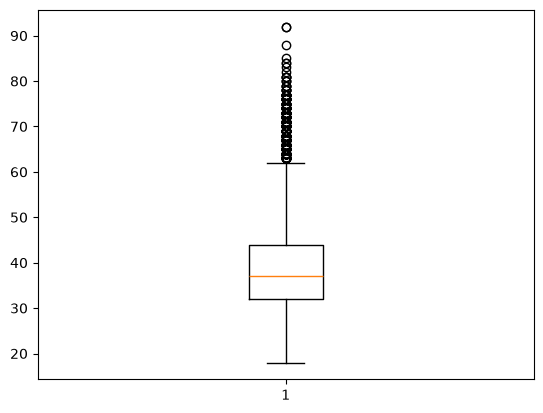

In [7]:
plt.boxplot(data['Age'])

In [9]:
data.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')

In [10]:
data.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1, inplace=True)

In [11]:
data['Geography'].unique()

<StringArray>
['France', 'Spain', 'Germany']
Length: 3, dtype: str

In [12]:
data['Gender'].unique()

<StringArray>
['Female', 'Male']
Length: 2, dtype: str

In [13]:
data['Geography'] = data['Geography'].replace({'France':0, 'Spain':1, 'Germany':2}).astype('int')

In [14]:
data['Gender'] = data['Gender'].replace({'Female':0, 'Male':1}).astype('int')

In [15]:
data.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,0,0,42,2,0.00,1,1,1,101348.88,1
1,608,1,0,41,1,83807.86,1,0,1,112542.58,0
2,502,0,0,42,8,159660.80,3,1,0,113931.57,1
3,699,0,0,39,1,0.00,2,0,0,93826.63,0
4,850,1,0,43,2,125510.82,1,1,1,79084.10,0


In [16]:
X = data.drop('Exited', axis=1)
y = data['Exited']

In [17]:
from imblearn.over_sampling import SMOTE

In [18]:
sm = SMOTE()
X, y = sm.fit_resample(X, y)

In [19]:
y.value_counts()

Exited
1    7963
0    7963
Name: count, dtype: int64

In [20]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 15926 entries, 0 to 15925
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      15926 non-null  int64  
 1   Geography        15926 non-null  int64  
 2   Gender           15926 non-null  int64  
 3   Age              15926 non-null  int64  
 4   Tenure           15926 non-null  int64  
 5   Balance          15926 non-null  float64
 6   NumOfProducts    15926 non-null  int64  
 7   HasCrCard        15926 non-null  int64  
 8   IsActiveMember   15926 non-null  int64  
 9   EstimatedSalary  15926 non-null  float64
dtypes: float64(2), int64(8)
memory usage: 1.2 MB


In [21]:
from sklearn.model_selection import train_test_split

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=7, test_size=0.2)

In [28]:
model = k.models.Sequential()

In [29]:
model.add(k.layers.Dense(units=10, activation='relu'))
model.add(k.layers.Dense(units=20, activation='relu'))
model.add(k.layers.Dense(units=1, activation='sigmoid'))
model.compile(loss='binary_crossentropy', metrics=['accuracy'], optimizer='adam')

In [30]:
model.fit(X_trian, y_train, epochs=15, batch_size=50)

Epoch 1/15
255/255 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5196 - loss: 865.6076
Epoch 2/15
255/255 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5180 - loss: 72.2902
Epoch 3/15
255/255 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5100 - loss: 52.4510
Epoch 4/15
255/255 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5188 - loss: 41.7686
Epoch 5/15
255/255 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5096 - loss: 51.3903
Epoch 6/15
255/255 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5191 - loss: 49.5943
Epoch 7/15
255/255 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5199 - loss: 49.5903
Epoch 8/15
255/255 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5169 - loss: 42.5327
Epoch 9/15
255/255 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5248 - loss: 36.8009
Epoch 10/15
255/255 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5197 - loss: 55.1815
Epoch 11/15
255/255 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5202 - loss: 42.8873
Epoch 12/15
255/255 ━━━━━━━━━━━━━━━━━━━━

In [31]:
model.evaluate(X_test, y_test)

100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5656 - loss: 40.4302


[40.43016052246094, 0.5655995011329651]

In [32]:
test_pred = model.predict(X_test)

100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [33]:
test_pred[0]

array([1.], dtype=float32)

In [34]:
label=[]
for value in test_pred:
    if(value >= 0.5):
        label.append(1)
    else:
        label.append(0)

In [35]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, label)

0.5655994978028877